# Simple model: hit or bust
Predict `success`: **1 = hit** (revenue at least 2.5 times budget), **0 = bust** (below that benchmark). Use logistic regression with fixed settings and a 0.5 probability threshold. Report hit precision, recall, and F1, alongside accuracy and ROC AUC.

Use **9 predictors instead of 39**, read from the existing feature-engineering output. The original baseline is fixed. Optional Section 5 compares six compact feature presets without changing estimator settings or the success threshold. Run from this folder with `ds6001`; no CSVs or model files are written.

## Tuning controls — edit here first

1. Edit the controls in the next cell.
2. **Save the notebook and Run All** so every result uses the same settings.
3. Review the validation table, then the later-test table. Do not repeatedly tune against test scores.

| What you want to change | Control |
|---|---|
| Original model or a setting not searched | `MODEL_SETTINGS` |
| Baseline inputs and small feature presets | `NUMERIC_FEATURES`, `BINARY_FEATURES`, and `FEATURE_SETS` |
| Required mean validation hit precision | `MIN_VALIDATION_PRECISION` (currently 0.70) |
| Final hit thresholds to test | `THRESHOLDS` |
| Date boundary and number of validation folds | `CUTOFF_DATE`, `N_VALIDATION_SPLITS`; keep consistent across models |

This simple model does not search hyperparameters. Changing `MODEL_SETTINGS` changes the fixed estimator in every preset; selection compares the configured feature presets and thresholds by F1 subject to the precision requirement.

**Example:** Edit a list in `FEATURE_SETS` to add/remove an input, keeping presets at most 10 predictors. Keep the original reference preset. Keep parameter key names unchanged when editing trial values.

In [1]:
# EDIT THIS CELL, then save and Run All. Do not change settings in later cells.
DATA_FILE = "../../data/model_data_success.csv"
CUTOFF_DATE = "2017-11-18"  # Change consistently across models for a fair comparison.
N_VALIDATION_SPLITS = 3     # Expanding chronological folds inside training.

# Fixed original-model settings. Grid values below override these during a search.
MODEL_SETTINGS = {'C': 1.0, 'max_iter': 3000, 'random_state': 42}

# Goal and threshold search. This is VALIDATION precision, not a test guarantee.
MIN_VALIDATION_PRECISION = 0.70
THRESHOLDS = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60,
              0.65, 0.70, 0.75, 0.80, 0.85, 0.90]
BASE_THRESHOLD = 0.5  # Original-reference predictions; estimator search uses predict() at 0.5.
assert 0 <= MIN_VALIDATION_PRECISION <= 1
assert THRESHOLDS and all(0 < value < 1 for value in THRESHOLDS)

# CHANGE THE FEATURE LISTS below to try small models (up to 10 inputs per preset).
NUMERIC_FEATURES = ["runtime", "dir_prior_films_log1p", "dir_prior_success_rate_smoothed", "dir_prior_known_films_log1p"]
CATEGORICAL_FEATURES = ["us_certification", "release_month"]
BINARY_FEATURES = ["is_sequel", "is_english", "dir_no_track_record"]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES

basics = ["runtime", "us_certification", "release_month", "is_sequel", "is_english"]
FEATURE_SETS = {
    "Movie basics": basics,
    "+ Director experience": basics + ["dir_prior_films_log1p"],
    "Original director history": FEATURE_COLUMNS,
    "Actor/company/franchise": basics + [
        "lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable",
        "company_films_5yr_log1p", "franchise_prior_films_log1p",
    ],
    "Basics + four genres": basics + ["genre_drama", "genre_comedy", "genre_action", "genre_horror"],
    "Compact mix": basics + [
        "dir_prior_success_rate_smoothed", "dir_prior_known_films_log1p", "dir_no_track_record",
        "lead_actor_films_5yr_backfilled_log1p", "company_films_5yr_log1p",
    ],
}

assert isinstance(N_VALIDATION_SPLITS, int) and N_VALIDATION_SPLITS >= 2

assert "Original director history" in FEATURE_SETS  # Keep the original reference preset.


## 1. Load data and choose nine predictors
Use runtime, director experience, smoothed success rate of observed earlier director films and the number with known financial outcomes, certification, release month, sequel status, English-language status, and a director-history availability flag.

Four numeric predictors, two categorical predictors, and three binary indicators keep the model small. Counts are already `log1p` transformed in the source table. Both current-movie targets and identifiers are excluded from predictors.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay

movies = pd.read_csv(DATA_FILE, parse_dates=["release_date"])
movies = movies.sort_values("release_date", kind="stable").reset_index(drop=True)
TARGET = "success"

assert FEATURE_COLUMNS and len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS))
assert not {"success", "vote_average", "tmdb_id", "imdb_id", "title_tmdb", "release_date", "budget", "revenue"} & set(FEATURE_COLUMNS)
assert movies["tmdb_id"].is_unique and movies["release_date"].notna().all()
assert movies[BINARY_FEATURES].isin([0, 1]).all().all()
X = movies[FEATURE_COLUMNS].copy()
for column in CATEGORICAL_FEATURES:
    X[column] = X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
y = movies[TARGET].copy()
assert y.notna().all()
print(f"{len(movies):,} movies | {len(FEATURE_COLUMNS)} predictors | Target: {TARGET}")
display(pd.DataFrame({
    "Predictor": FEATURE_COLUMNS,
    "Role": ["Numeric"] * len(NUMERIC_FEATURES) + ["Categorical"] * len(CATEGORICAL_FEATURES) + ["Binary"] * len(BINARY_FEATURES),
}))
assert y.isin([0, 1]).all()

6,919 movies | 9 predictors | Target: success


,Predictor,Role
0,runtime,Numeric
1,dir_prior_films_log1p,Numeric
2,dir_prior_success_rate_smoothed,Numeric
3,dir_prior_known_films_log1p,Numeric
4,us_certification,Categorical
5,release_month,Categorical
6,is_sequel,Binary
7,is_english,Binary
8,dir_no_track_record,Binary


## 2. Split chronologically
Use the same earlier approximately 80% for training and later 20% for testing as the other models. Equal release dates stay together.

In [3]:
cutoff = pd.Timestamp(CUTOFF_DATE)
train = movies["release_date"].lt(cutoff)
test = ~train
X_train, X_test = X.loc[train], X.loc[test]
y_train, y_test = y.loc[train], y.loc[test]
assert movies.loc[train, "release_date"].max() < movies.loc[test, "release_date"].min()
assert set(movies.loc[train, "tmdb_id"]).isdisjoint(movies.loc[test, "tmdb_id"])
display(pd.DataFrame([
    ["Training", len(y_train), movies.loc[train, "release_date"].min(), movies.loc[train, "release_date"].max()],
    ["Test", len(y_test), movies.loc[test, "release_date"].min(), movies.loc[test, "release_date"].max()],
], columns=["Split", "Movies", "First release", "Last release"]))

,Split,Movies,First release,Last release
0,Training,5535,1990-01-12,2017-11-17
1,Test,1384,2017-11-18,2025-12-25


## 3. Fit Logistic regression
Build the original reference model with **`MODEL_SETTINGS` in the top Tuning controls cell**. Change searched values in `PARAM_GRID` where available; values in that grid override the original settings during search. The simple notebooks keep the estimator fixed across feature presets.

Imputation, scaling, and categorical encoding are fitted on training data only. Binary flags pass through unchanged. No current-movie outcome is a predictor.

In [4]:
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), NUMERIC_FEATURES),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ]), CATEGORICAL_FEATURES),
    ("binary", "passthrough", BINARY_FEATURES),
])
model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(**MODEL_SETTINGS)),
])
model.fit(X_train, y_train)
THRESHOLD = BASE_THRESHOLD
train_probability = model.predict_proba(X_train)[:, list(model.classes_).index(1)]
test_probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
train_prediction = (train_probability >= THRESHOLD).astype(int)
test_prediction = (test_probability >= THRESHOLD).astype(int)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_prediction = baseline.predict(np.zeros((len(y_test), 1)))
baseline_probability = baseline.predict_proba(np.zeros((len(y_test), 1)))[:, list(baseline.classes_).index(1)]

## 4. Evaluate
Compare the training and later-test results with a simple baseline, then inspect the first ten test predictions.

,Model,Split,Accuracy,Balanced accuracy,Hit precision,Hit recall,Hit F1,ROC AUC
0,Majority baseline,Test,0.6568,0.5000,0.0000,0.0000,0.0000,0.5000
1,Simple logistic regression,Training,0.6676,0.5789,0.6165,0.2464,0.3521,0.6617
2,Simple logistic regression,Test,0.6655,0.5940,0.5179,0.3663,0.4291,0.6608


,title_tmdb,success,hit_probability,predicted_success
5535,Revenge,0,0.487,0
5536,Darkest Hour,1,0.383,0
5537,"Three Billboards Outside Ebbing, Missouri",1,0.302,0
5538,The Shape of Water,1,0.319,0
5539,Wonder Wheel,0,0.296,0
5540,Molly's Game,0,0.494,0
5541,"I, Tonya",1,0.257,0
5542,Ferdinand,1,0.599,1
5543,Star Wars: The Last Jedi,1,0.775,1
5544,Loving Pablo,1,0.383,0


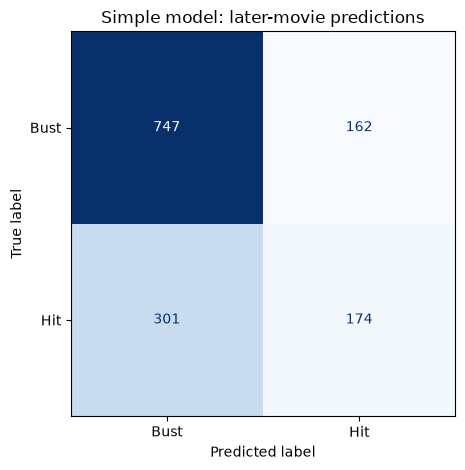

In [5]:
def score(name, split, actual, predicted, probability):
    return {
        "Model": name, "Split": split,
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced accuracy": balanced_accuracy_score(actual, predicted),
        "Hit precision": precision_score(actual, predicted, zero_division=0),
        "Hit recall": recall_score(actual, predicted, zero_division=0),
        "Hit F1": f1_score(actual, predicted, zero_division=0),
        "ROC AUC": roc_auc_score(actual, probability),
    }
results = pd.DataFrame([
    score("Majority baseline", "Test", y_test, baseline_prediction, baseline_probability),
    score("Simple logistic regression", "Training", y_train, train_prediction, train_probability),
    score("Simple logistic regression", "Test", y_test, test_prediction, test_probability),
])
display(results.round(4))
examples = movies.loc[test, ["title_tmdb", "success"]].copy()
examples["hit_probability"] = test_probability
examples["predicted_success"] = test_prediction
display(examples.head(10).round(3))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_prediction, labels=[0, 1], display_labels=["Bust", "Hit"],
    cmap="Blues", colorbar=False,
)
plt.title("Simple model: later-movie predictions")
plt.tight_layout()
plt.show()

## 5. Try small feature sets at 0.70 validation precision
Compare six compact feature presets using identical logistic regression settings and three expanding training-period chronological folds. For each, test thresholds 0.30–0.90 by 0.05. Require **mean validation hit precision at least 0.70**, then select the highest mean hit F1. If no candidate qualifies, report infeasibility and retain the original nine-feature model only as a labeled reference.

The first four sections remain the fixed-threshold baseline. The 0.70 requirement is set before evaluating later outcomes and does not guarantee later test precision. F1 balances recall and precision, while the separate guard prioritizes precision. Selection remains exploratory on previously inspected data.

**Change settings in the Tuning controls cell at the top, save, then Run All. The code below uses those settings; do not redefine them here.**

In [6]:
from sklearn.model_selection import TimeSeriesSplit

feature_versions = FEATURE_SETS
assert all(len(columns) <= 10 and len(columns) == len(set(columns)) for columns in feature_versions.values())
comparison_features = list(dict.fromkeys(column for columns in feature_versions.values() for column in columns))
assert not {"success", "vote_average", "tmdb_id", "imdb_id", "title_tmdb", "release_date", "budget", "revenue"} & set(comparison_features)
comparison_X = movies[comparison_features].copy()
for column in CATEGORICAL_FEATURES:
    comparison_X[column] = comparison_X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
comparison_binary = BINARY_FEATURES + ["backfill_unavailable"] + [column for column in movies if column.startswith("genre_")]

# Same model and preprocessing rules for every preset.
def make_feature_model(columns):
    numeric = [column for column in columns if column not in CATEGORICAL_FEATURES + comparison_binary]
    categorical = [column for column in CATEGORICAL_FEATURES if column in columns]
    binary = [column for column in columns if column in comparison_binary]
    return Pipeline([
        ("preprocessor", ColumnTransformer([
            ("numeric", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]), numeric),
            ("categorical", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
            ]), categorical),
            ("binary", "passthrough", binary),
        ])),
        ("model", LogisticRegression(**MODEL_SETTINGS)),
    ])

training_dates = movies.loc[train, "release_date"]
unique_dates = np.sort(training_dates.unique())
feature_splits = []
for earlier, later in TimeSeriesSplit(n_splits=N_VALIDATION_SPLITS).split(unique_dates):
    fit_rows = training_dates.index[training_dates.isin(unique_dates[earlier])]
    validation_rows = training_dates.index[training_dates.isin(unique_dates[later])]
    assert movies.loc[fit_rows, "release_date"].max() < movies.loc[validation_rows, "release_date"].min()
    assert set(fit_rows).union(validation_rows).issubset(set(y_train.index))
    feature_splits.append((fit_rows, validation_rows))

fold_results = []
for version, columns in feature_versions.items():
    for fold, (fit_rows, validation_rows) in enumerate(feature_splits, 1):
        candidate = make_feature_model(columns)
        candidate.fit(comparison_X.loc[fit_rows], y.loc[fit_rows])
        probability = candidate.predict_proba(comparison_X.loc[validation_rows])[:, list(candidate.classes_).index(1)]
        for candidate_threshold in THRESHOLDS:
            predicted = (probability >= candidate_threshold).astype(int)
            metrics = score(version, "Validation", y.loc[validation_rows], predicted, probability)
            fold_results.append({"Version": version, "Threshold": candidate_threshold, "Fold": fold, "Predictors": len(columns), **{key: metrics[key] for key in ["Hit precision", "Hit recall", "Hit F1", "Balanced accuracy", "Accuracy", "ROC AUC"]}})
feature_fold_results = pd.DataFrame(fold_results)
feature_comparison = feature_fold_results.groupby(["Version", "Threshold"], sort=False).agg(
    Predictors=("Predictors", "first"),
    Precision=("Hit precision", "mean"), Recall=("Hit recall", "mean"),
    F1=("Hit F1", "mean"), F1_std=("Hit F1", "std"),
    Balanced_accuracy=("Balanced accuracy", "mean"), Accuracy=("Accuracy", "mean"),
    ROC_AUC=("ROC AUC", "mean"),
)
precision_floor = float(MIN_VALIDATION_PRECISION)
feature_comparison["Meets precision guard"] = feature_comparison["Precision"].ge(precision_floor - 1e-12)
eligible = feature_comparison.loc[feature_comparison["Meets precision guard"]]
precision_requirement_met = not eligible.empty
max_validation_precision = float(feature_comparison["Precision"].max())
if precision_requirement_met:
    selected_version, selected_threshold = eligible.sort_values(["F1", "Precision"], ascending=False, kind="stable").index[0]
    selection_status = "Precision/F1-selected simple model"
    display(eligible.sort_values("F1", ascending=False).head(12).round(4))
else:
    selected_version, selected_threshold = "Original director history", THRESHOLD
    selection_status = "Original baseline (precision target infeasible)"
    print("No simple candidate meets the configured validation precision; original baseline retained for reference only.")
    display(feature_comparison.sort_values("Precision", ascending=False).head(5).round(4))
print(f"Required precision: {precision_floor:.2f}; maximum mean validation precision: {max_validation_precision:.3f}")
print("Selected using training-period validation:", selected_version, "threshold:", selected_threshold)
selected_columns = feature_versions[selected_version]
print("Selected predictors:", selected_columns)

feature_selected_model = make_feature_model(selected_columns)
feature_selected_model.fit(comparison_X.loc[train], y_train)
selected_probability = feature_selected_model.predict_proba(comparison_X.loc[test])[:, list(feature_selected_model.classes_).index(1)]
selected_prediction = (selected_probability >= selected_threshold).astype(int)
selected_test_result = score(selection_status, "Test", y_test, selected_prediction, selected_probability)
comparison_test_results = pd.concat([results.loc[results["Split"].eq("Test")], pd.DataFrame([selected_test_result])], ignore_index=True)
display(comparison_test_results.round(4))
print("The original model above is retained. Lower test errors or higher classification scores are not guaranteed by validation selection.")
assert len(feature_fold_results) == len(feature_versions) * N_VALIDATION_SPLITS * len(THRESHOLDS)

,,Predictors,Precision,Recall,F1,F1_std,Balanced_accuracy,Accuracy,ROC_AUC,Meets precision guard
Version,Threshold,,,,,,,,,
Original director history,0.70,9,0.7167,0.0413,0.0774,0.0480,0.5163,0.6335,0.6436,True
Compact mix,0.70,10,0.7194,0.0321,0.0611,0.0405,0.5128,0.6314,0.6443,True
+ Director experience,0.70,6,0.7046,0.0268,0.0515,0.0121,0.5097,0.6282,0.6348,True
Original director history,0.75,9,0.7141,0.0161,0.0314,0.0119,0.5061,0.6266,0.6436,True
Basics + four genres,0.75,9,0.7778,0.0055,0.0109,0.0066,0.5020,0.6239,0.6377,True


Required precision: 0.70; maximum mean validation precision: 0.778
Selected using training-period validation: Original director history threshold: 0.7
Selected predictors: ['runtime', 'dir_prior_films_log1p', 'dir_prior_success_rate_smoothed', 'dir_prior_known_films_log1p', 'us_certification', 'release_month', 'is_sequel', 'is_english', 'dir_no_track_record']


,Model,Split,Accuracy,Balanced accuracy,Hit precision,Hit recall,Hit F1,ROC AUC
0,Majority baseline,Test,0.6568,0.5000,0.0000,0.0000,0.0000,0.5000
1,Simple logistic regression,Test,0.6655,0.5940,0.5179,0.3663,0.4291,0.6608
2,Precision/F1-selected simple model,Test,0.6749,0.5464,0.6190,0.1368,0.2241,0.6608


The original model above is retained. Lower test errors or higher classification scores are not guaranteed by validation selection.


## Interpretation
Precision is how often a predicted hit is truly a hit; recall is how many actual hits are found. Hit F1 balances both equally. The fixed 0.5 threshold is a simple baseline, not a precision-optimized decision rule. Compare with the more detailed notebooks, which select features, settings, and thresholds through validation.

History covers observed earlier films and uses retrospective snapshots, not a complete director filmography or verified historical ratings/outcomes. Earlier-year histories update through time, representing rolling predictions. Results describe the financially eligible cohort and the already-inspected later period, so they are exploratory. Keep the same evaluation rows when comparing simple and detailed models.

## Refresh the visualization report
This final cell saves metrics and prediction summaries for [the visualization notebook](../../Data_visualization/model_visualizations.ipynb). It does not write or modify dataset CSVs. Save this notebook before running all cells so report freshness checks match the code.

In [7]:
from pathlib import Path
import importlib.util

report_module_path = Path("../../Data_visualization/model_reports.py")
report_spec = importlib.util.spec_from_file_location("project_model_reports", report_module_path)
report_tools = importlib.util.module_from_spec(report_spec)
report_spec.loader.exec_module(report_tools)
report_path = report_tools.save_model_report(globals(), Path("simple_model.ipynb"))
print("Visualization report saved:", report_path)

Visualization report saved: /Users/waltroou/DS-6021/DS_Final_Project/DS6021_Group2_FinalProject/Data_visualization/results/success/simple_model.json
